<a href="https://colab.research.google.com/github/luka4-lab/linear-Regression/blob/main/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving bsas_realstate_on_sale_properati_dataset_2020.csv to bsas_realstate_on_sale_properati_dataset_2020.csv


In [62]:
import pandas as pd
def wrangle(filepath):
  df=pd.read_csv(filepath)
    #lets remain l3 to neighborhoood
  df.rename(columns={"l3": "neighborhood"}, inplace=True)
  # remain L2 to place_with_parents name
  df.rename(columns={"l2":"place_with_parent_name"},inplace=True)
  # lets select place_with_parent_name in capital federal only
  mask_ca=df["place_with_parent_name"].str.contains("Capital Federal")
  # lets take property containing departamento
  mask_da=df["property_type"]=="Departamento"
  # propert that have less than 400_000
  mask_price=df["price"]<400_000
  df=df[mask_ca& mask_da&mask_price]
  #remove outlier
  low,high==df['surface_covered'].quantile([0.1,0.9])
  mask_area=df["surface_covered"].between(low,high)
  df=df[mask_area]
  ##lets drop columns with high nan values
  df.drop(columns=["bathrooms","surface_covered"],inplace=True)
  #lets drop low and high cardinilaty
  drop_cols = [
      "l1",
      "place_with_parent_name",
     "currency",
      "property_type",
      "operation_type",
      "title",
      "description"
  ]

  df.drop(columns=drop_cols, inplace=True)
  #lets drop future leakage data redudant  respectively
  df.drop(columns=["end_date","start_date","created_on"],inplace=True)
  #lets drop multicollinearity
  df.drop(columns=["rooms","bedrooms","surface_total"],inplace=True)


  return df

In [57]:
df=wrangle("bsas_realstate_on_sale_properati_dataset_2020.csv")
df.shape
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 49770 entries, 11 to 146545
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   lat            47411 non-null  float64
 1   lon            47411 non-null  float64
 2   neighborhood   49770 non-null  object 
 3   rooms          49770 non-null  float64
 4   bedrooms       49770 non-null  float64
 5   surface_total  49671 non-null  float64
 6   price          49770 non-null  float64
dtypes: float64(6), object(1)
memory usage: 3.0+ MB


,lat,lon,neighborhood,rooms,bedrooms,surface_total,price
11,-34.603683,-58.381557,Boedo,2.0,1.0,68.0,149000.0
12,-34.630349,-58.417223,Boedo,2.0,1.0,50.0,115000.0
22,-34.626240,-58.462078,Flores,2.0,1.0,45.0,95000.0
23,-34.625611,-58.462403,Flores,2.0,1.0,45.0,95000.0
24,-34.636661,-58.471170,Flores,2.0,1.0,58.0,154000.0


In [20]:
df["l3"].unique()[:5]

array(['San Cristobal', 'Boedo', 'Palermo', 'La Plata', 'Villa Crespo'],
      dtype=object)

In [21]:
#lets remain l3 to neighborhoood
df.rename(columns={"l3": "neighborhood"}, inplace=True)

In [23]:
# remain L2 to place_with_parents name
df.rename(columns={"l2":"place_with_parent_name"},inplace=True)

In [24]:
df["l1"].unique()

array(['Argentina'], dtype=object)

In [25]:
df["place_with_parent_name"].unique()

array(['Capital Federal', 'Bs.As. G.B.A. Zona Sur',
       'Bs.As. G.B.A. Zona Norte', 'Bs.As. G.B.A. Zona Oeste'],
      dtype=object)

In [26]:
# lets select place_with_parent_name in capital federal only
mask_ca=df["place_with_parent_name"].str.contains("Capital Federal")
df[mask_ca].head()

,lat,lon,l1,place_with_parent_name,neighborhood,bathrooms,surface_covered,price,currency,title,description,property_type,operation_type
0,-34.605880,-58.384949,Argentina,Capital Federal,San Cristobal,2.0,140.0,153000.0,USD,"***Venta semipiso centro, ideal hostel*****",DESCRIPCION DE LA PROPIEDAD: Departamento de 1...,Departamento,Venta
1,-34.624056,-58.412110,Argentina,Capital Federal,Boedo,2.0,58.0,159000.0,USD,Espectacular PH reciclado en Boedo sin expensas.,PH reciclado en Boedo a una cuadra de la plaz...,PH,Venta
2,-34.593569,-58.427474,Argentina,Capital Federal,Palermo,1.0,45.0,125000.0,USD,Depto.tipo casa de 2 ambientes en Venta en Pal...,"2 ambienets amplio , excelente estado , patio ...",PH,Venta
3,-34.581294,-58.436754,Argentina,Capital Federal,Palermo,1.0,50.0,295000.0,USD,COSTA RICA 5800 / PALERMO HOLLYWOOD / VENTA PH...,HERMOSO PH EN PALERMO!!!2 AMBIENTES TOTALMENTE...,PH,Venta
5,-34.593779,-58.441239,Argentina,Capital Federal,Villa Crespo,1.0,56.0,150000.0,USD,Depto.tipo casa de 2 ambientes en Venta en Vil...,"Excelente ph solo 2 unidades, no paga expensas...",PH,Venta


In [27]:
df["property_type"].unique()

array(['Departamento', 'PH', 'Casa', 'Lote', 'Casa de campo', 'Oficina',
       'Otro', 'Local comercial', 'Cochera', 'Depósito'], dtype=object)

In [29]:
# lets take property containing departamento
df["property_type"]=="Departamento"

,property_type
0,True
1,False
2,False
3,False
4,False
...,...
146655,True
146656,True
146657,True
146658,True


In [30]:
# propert that have less than 400_000
mask_price=df["price"]<400_000

In [31]:
#lets look for an outlier
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

Text(0.5, 1.0, 'Distribution of apartment size')

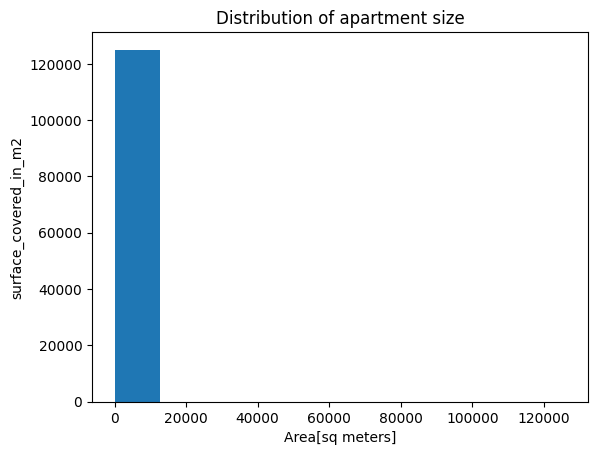

In [32]:
plt.hist(df["surface_covered"])
plt.xlabel("Area[sq meters]")
plt.ylabel("surface_covered_in_m2")
plt.title("Distribution of apartment size")

In [35]:
df.describe()["surface_covered"]

,surface_covered
count,60935.000000
mean,71.499286
std,519.893191
min,1.000000
25%,41.000000
50%,54.000000
75%,74.000000
max,104890.000000


In [36]:
low,high=df["surface_covered"].quantile([0.1,0.9])
print(low,high)

34.0 97.0


In [37]:
mask_area=df["surface_covered"].between(low, high)

Create a scatter plot that shows price ("price_aprox_usd") vs area ("surface_covered_in_m2") in our dataset. Make sure to label your x-axis "Area [sq meters]" and your y-axis "Price [USD]".

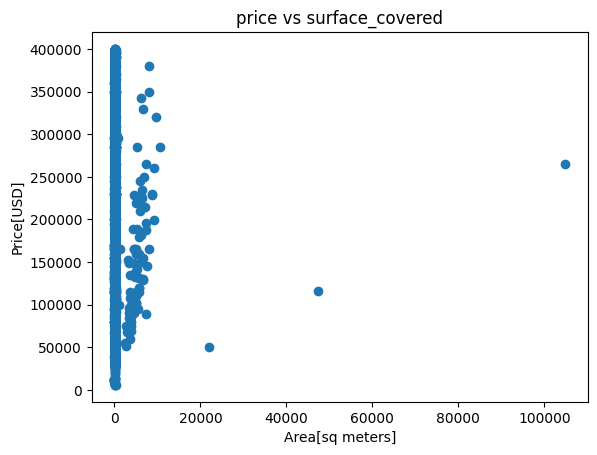

In [39]:
plt.scatter(
    x=df["surface_covered"],
    y=df["price"]

)
plt.xlabel("Area[sq meters]")
plt.ylabel("Price[USD]")
plt.title("price vs surface_covered")
plt.show();


In [40]:
fig = px.scatter_mapbox(
    df,  # Our DataFrame
    lat="lat",
    lon="lon",
    width=600,  # Width of map
    height=600,  # Height of map
    color="price",
    hover_data=["price"],  # Display price when hovering mouse over house
)

fig.update_layout(mapbox_style="open-street-map")

fig.show()

In [41]:
# Create 3D scatter plot
fig = px.scatter_3d(
    df,
    x="lon",
    y="lat",
    z="price",
    labels={"lon": "longitude", "lat": "latitude", "price_aprox_usd": "price"},
    width=600,
    height=500,
)

# Refine formatting
fig.update_traces(
    marker={"size": 4, "line": {"width": 2, "color": "DarkSlateGrey"}},
    selector={"mode": "markers"},
)

# Display figure
fig.show()

In [42]:
df.isnull().sum()

,0
start_date,0
end_date,0
created_on,0
lat,3076
lon,3085
l1,0
place_with_parent_name,0
neighborhood,0
rooms,0
bedrooms,0


In [43]:
#lets drop columns with high nan values
df.drop(columns=["bathrooms","surface_covered"],inplace=True)

In [44]:
df.select_dtypes("object").nunique().sort_values()

,0
l1,1
place_with_parent_name,1
currency,1
property_type,1
operation_type,1
neighborhood,57
start_date,362
created_on,362
end_date,407
title,31823


In [45]:
df.columns.tolist()

['start_date',
 'end_date',
 'created_on',
 'lat',
 'lon',
 'l1',
 'place_with_parent_name',
 'neighborhood',
 'rooms',
 'bedrooms',
 'surface_total',
 'price',
 'currency',
 'title',
 'description',
 'property_type',
 'operation_type']

In [46]:
#lets drop low and high cardinilaty
drop_cols = {
    "l1",
    "place_with_parent_name",
    "currency",
    "title",
    "description"
}
df.drop(columns=drop_cols, inplace=True)

In [51]:

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49770 entries, 11 to 146545
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   start_date     49770 non-null  object 
 1   end_date       49770 non-null  object 
 2   created_on     49770 non-null  object 
 3   lat            47411 non-null  float64
 4   lon            47411 non-null  float64
 5   neighborhood   49770 non-null  object 
 6   rooms          49770 non-null  float64
 7   bedrooms       49770 non-null  float64
 8   surface_total  49671 non-null  float64
 9   price          49770 non-null  float64
dtypes: float64(6), object(4)
memory usage: 5.2+ MB


In [52]:
df[["start_date", "end_date", "created_on"]].head(10)

,start_date,end_date,created_on
11,2019-10-17,2019-10-26,2019-10-17
12,2019-10-17,2019-12-19,2019-10-17
22,2019-10-17,2019-11-13,2019-10-17
23,2019-10-17,2019-12-23,2019-10-17
24,2019-10-17,2019-12-23,2019-10-17
25,2019-10-17,2019-12-23,2019-10-17
27,2019-10-17,2019-12-23,2019-10-17
29,2019-10-17,2019-11-01,2019-10-17
30,2019-10-17,2019-10-31,2019-10-17
33,2019-10-17,2019-11-01,2019-10-17


In [53]:
(df["start_date"] == df["created_on"]).all()

np.True_

In [54]:
#lets drop future leakage data redudant  respectively
df.drop(columns=["end_date","start_date","created_on"],inplace=True)

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49770 entries, 11 to 146545
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   lat            47411 non-null  float64
 1   lon            47411 non-null  float64
 2   neighborhood   49770 non-null  object 
 3   rooms          49770 non-null  float64
 4   bedrooms       49770 non-null  float64
 5   surface_total  49671 non-null  float64
 6   price          49770 non-null  float64
dtypes: float64(6), object(1)
memory usage: 3.0+ MB


In [59]:
corr = df[["lat", "lon", "rooms", "surface_total", "price","bedrooms"]].drop(columns="price").corr()
corr

,lat,lon,rooms,surface_total,bedrooms
lat,1.000000,-0.164110,-0.056357,0.002199,-0.061668
lon,-0.164110,1.000000,0.056718,-0.002673,0.051556
rooms,-0.056357,0.056718,1.000000,0.030224,0.924714
surface_total,0.002199,-0.002673,0.030224,1.000000,0.029511
bedrooms,-0.061668,0.051556,0.924714,0.029511,1.000000


<Axes: >

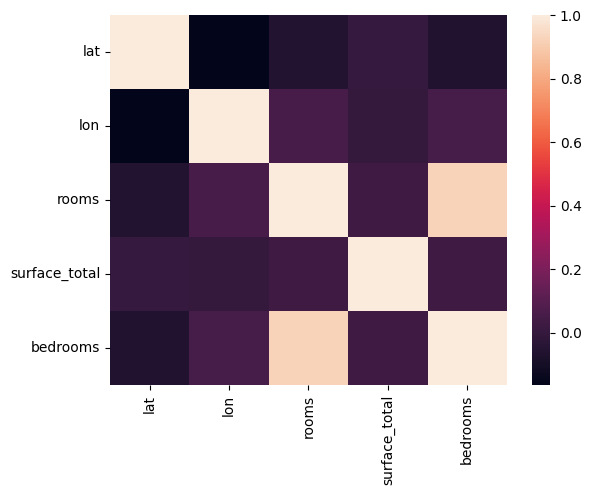

In [60]:
sns.heatmap(corr)

In [61]:
#lets drop multicollinearity
df.drop(columns=["rooms","bedrooms"],inplace=True)

In [63]:
#split
target="price"
y_train=df[target]
y_train.shape

(49770,)

In [64]:
feature=["lat","lon","neighborhood"]
X_train=df[feature]
X_train.shape

(49770, 3)

In [65]:
y_mean=y_train.mean()

In [66]:
y_pred_baseline=[y_mean]*len(y_train)

In [67]:
from sklearn.metrics import mean_absolute_error
mae_baseline=mean_absolute_error(y_train,y_pred_baseline)
print("Mean apt price:", round(y_mean, 2))
print("Baseline MAE:", round(mae_baseline, 2))

Mean apt price: 171500.96
Baseline MAE: 54427.58


In [68]:
!pip install category_encoders
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.impute import SimpleImputer
from category_encoders import OneHotEncoder

In [69]:
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    SimpleImputer(),
    Ridge()
)

In [70]:
model.fit(X_train,y_train)

Pipeline(steps=[('onehotencoder',
                 OneHotEncoder(cols=['neighborhood'], use_cat_names=True)),
                ('simpleimputer', SimpleImputer()), ('ridge', Ridge())])

In [71]:
y_pred_training=model.predict(X_train)

In [72]:
mae_baseline=mean_absolute_error(y_train,y_pred_training)
print("Mean apt price:", round(y_mean, 2))
print("Baseline MAE:", round(mae_baseline, 2))

Mean apt price: 171500.96
Baseline MAE: 46797.69


In [73]:
intercept=model.named_steps["ridge"].intercept_
intercept

np.float64(25635503.30291588)

In [74]:
coeefficients=model.named_steps["ridge"].coef_
coeefficients[:5]

array([383773.67366436, 208845.62246761, -19299.38266956,   2377.82845204,
        33857.1801225 ])

In [75]:
feature_names = model.named_steps["onehotencoder"].get_feature_names_out()

feature_names[:5]

array(['lat', 'lon', 'neighborhood_Boedo', 'neighborhood_Flores',
       'neighborhood_Nuñez'], dtype=object)

In [76]:
def make_prediction(area, lat, lon, neighborhood):
    data = {

        "surface_total": area,
        "lat": lat,
        "lon": lon,
        "neighborhood": neighborhood
    }

    df = pd.DataFrame(data, index=[0])
    prediction = model.predict(df)

    return f"Predicted apartment price: ${prediction[0]:,.2f}"

In [77]:
def make_prediction(lat, lon, neighborhood):
    data = {
        "lat": lat,
        "lon": lon,
        "neighborhood": neighborhood
    }

    df = pd.DataFrame(data, index=[0])
    prediction = model.predict(df)

    return f"Predicted apartment price: ${prediction[0]:,.2f}"

# Run the prediction using the corrected function parameters
make_prediction(-34.60, -58.46, "Villa Crespo")

'Predicted apartment price: $141,999.77'

In [78]:
from ipywidgets import interact, FloatSlider, Dropdown

interact(
    make_prediction,
    lat=FloatSlider(
        min=X_train["lat"].min(),
        max=X_train["lat"].max(),
        step=0.01,
        value=X_train["lat"].mean(),
    ),
    lon=FloatSlider(
        min=X_train["lon"].min(),
        max=X_train["lon"].max(),
        step=0.01,
        value=X_train["lon"].mean(),
    ),
    neighborhood=Dropdown(options=sorted(X_train["neighborhood"].unique())),
);

interactive(children=(FloatSlider(value=-34.597891354081895, description='lat', max=-34.535909000000004, min=-…